# ICL 예시 이미지 확인 노트북

SoM VLM 파이프라인(`zeroshot_som.py`/`sft_som.py`/`rl_som.py`)이 ICL(in-context learning) 예시로
**실제로 어떤 이미지를 어떤 형식으로** 모델에 넣는지 눈으로 확인하기 위한 노트북이다.

- 예시 이미지 자체(SoM + mosaic 한 쌍)는 데이터셋에서 `pick_exemplars()`가 고른 걸 그대로 씀.
- 같은 예시 이미지라도 **어디서 쓰이느냐에 따라 정답 포맷이 다름**:
  - zs/icl(`--icl`) 평가: 마크 전체에 대한 최종 라벨(`labels_json`) — `icl_messages()`
  - sft/rl 학습: 그 step에서 고른 부분과제(dedup/filt/unripe/ripe_semi 또는 2cls의 ripe_unripe) 라벨만 — `icl_stage()`
- 마지막 셀에서 실제 모델에 들어가는 `messages` 리스트(role/content) 구조까지 그대로 출력한다.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebook" else Path.cwd()
sys.path.insert(0, str(ROOT))
sys.path.insert(0, str(ROOT / "src/llm-classify"))

import som_common
import som_dataset

## 1. 데이터셋/proposal/클래스 목록 설정

`sft_som.py`/`rl_som.py`가 실제로 부르는 것과 동일한 순서(`set_marker_style` → `set_class_list` →
`load_split` → proposal 로드 → `label_props` → `pick_exemplars`)로 그대로 재현한다.

In [2]:
DATASET = "little"          # ag_rob_tomato / little / tomatod (3cls) 또는 custom_tomato / rob2pheno (2cls)
MARKER_STYLE = "id_only"     # Stage-1로 확정된 값
PROPOSAL_SOURCE = "yolo_world_1cls"
N_EXEMPLARS = 2

som_common.set_marker_style(MARKER_STYLE)
som_common.set_class_list(som_dataset.resolve_class_list(DATASET))
print("class_list:", som_common.TOMATO_CLASSES)
print("stage_names (sft/rl이 고르는 부분과제):", som_common.SomPrompts.stage_names())

marker_style=id_only
class_list: ('fully-ripe', 'semi-ripe', 'unripe')
stage_names (sft/rl이 고르는 부분과제): ('dedup', 'filt', 'unripe', 'ripe_semi')


In [3]:
train_raw = som_dataset.load_split(DATASET, "train")
prompts = som_common.SomPrompts(train_raw)

# train은 --proposal-source 캐시가 아니라 sft_som.py/rl_som.py와 동일하게 항상 live YOLO로
# proposal을 뽑는다(config/vlm_som/sft_qwen35_27b.yaml: family=yolo_world, conf=0.1) --
# 노트북 용도라 처음 40장만 빠르게 수집한다 (exemplar 몇 장 고르는 데는 충분).
GPU = 2
train_raw = train_raw[:40]
proposals = som_dataset.collect_proposals(
    DATASET, train_raw, ROOT / "notebook/.icl_inspect_train_proposals_cache.json",
    family="yolo_world", conf=0.1, max_n=20, device=GPU,
)

def _labeled(it):
    return som_common.label_props(it, proposals.get(it["path"], []), prompts.small_rel, prompts.small_side)

exemplars = som_common.pick_exemplars(train_raw, _labeled, n=N_EXEMPLARS)
print(f"뽑힌 exemplar {len(exemplars)}장:")
for i, ex in enumerate(exemplars, 1):
    print(f"  [{i}] {Path(ex['path']).name}  labels={ex['labels']}")

뽑힌 exemplar 2장:
  [1] IMG_1133.jpg  labels=['unripe', 'fully-ripe', 'unripe', 'fully-ripe', 'unripe', 'unripe', 'fully-ripe', 'unripe', 'fully-ripe', 'unripe', 'semi-ripe', 'unripe', 'unripe', 'fully-ripe', 'fully-ripe', 'fully-ripe', 'unripe', 'fully-ripe', 'unripe', 'fully-ripe']
  [2] IMG_1181.jpg  labels=['unripe', 'unripe', 'unripe', 'unripe', 'unripe', 'unripe', 'unripe', 'unripe', 'unripe', 'unripe', 'unripe', 'unripe', 'unripe', 'unripe', 'unripe', 'unripe', 'unripe', 'unripe', 'unripe', 'unripe']


## 2. 예시 이미지 자체 (SoM + mosaic)

실제로 모델에 두 장씩(왼쪽 SoM, 오른쪽 mosaic) 들어간다 — `pair_images()`가 만드는 바로 그 이미지.

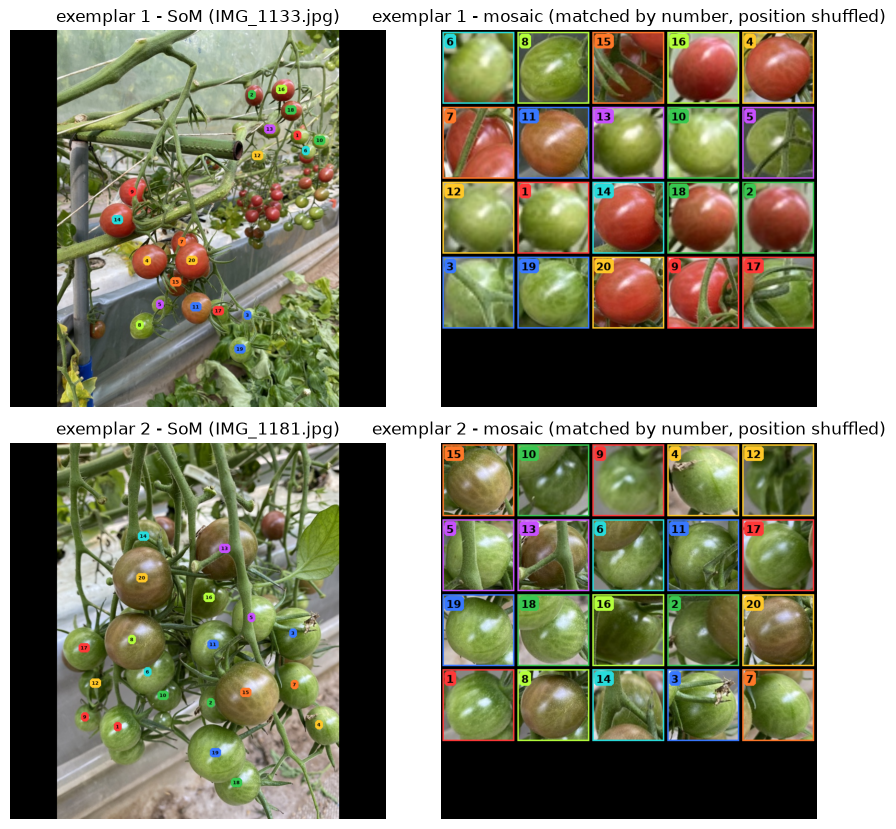

In [4]:
fig, axes = plt.subplots(len(exemplars), 2, figsize=(9, 4.2 * len(exemplars)))
if len(exemplars) == 1:
    axes = axes[None, :]
for i, ex in enumerate(exemplars):
    som_img, mosaic_img = som_common.pair_images(ex)
    axes[i, 0].imshow(som_img)
    axes[i, 0].set_title(f"exemplar {i+1} - SoM ({Path(ex['path']).name})")
    axes[i, 0].axis("off")
    axes[i, 1].imshow(mosaic_img)
    axes[i, 1].set_title(f"exemplar {i+1} - mosaic (matched by number, position shuffled)")
    axes[i, 1].axis("off")
plt.tight_layout()
plt.show()

## 3. (A) zs/icl 평가용 포맷 — `icl_messages()`

`--icl` 플래그가 켜진 zeroshot_som.py가 실제로 쓰는 형식. 마크 전체에 대한 **최종 라벨**을
정답으로 보여준다(`labels_json`) — reasoning 필드는 exemplar 정답에는 없다(질의 시점에만 요구).

In [5]:
for i, ex in enumerate(exemplars, 1):
    print(f"--- exemplar {i} 정답(full-task, icl_messages/labels_json) ---")
    print(prompts.labels_json(ex))

--- exemplar 1 정답(full-task, icl_messages/labels_json) ---
{'1': 'unripe', '2': 'fully-ripe', '3': 'unripe', '4': 'fully-ripe', '5': 'unripe', '6': 'unripe', '7': 'fully-ripe', '8': 'unripe', '9': 'fully-ripe', '10': 'unripe', '11': 'semi-ripe', '12': 'unripe', '13': 'unripe', '14': 'fully-ripe', '15': 'fully-ripe', '16': 'fully-ripe', '17': 'unripe', '18': 'fully-ripe', '19': 'unripe', '20': 'fully-ripe'}
--- exemplar 2 정답(full-task, icl_messages/labels_json) ---
{'1': 'unripe', '2': 'unripe', '3': 'unripe', '4': 'unripe', '5': 'unripe', '6': 'unripe', '7': 'unripe', '8': 'unripe', '9': 'unripe', '10': 'unripe', '11': 'unripe', '12': 'unripe', '13': 'unripe', '14': 'unripe', '15': 'unripe', '16': 'unripe', '17': 'unripe', '18': 'unripe', '19': 'unripe', '20': 'unripe'}


## 4. (B) sft/rl 학습용 포맷 — `icl_stage()`

**같은 예시 이미지**를 두고, 그 step에서 고른 부분과제(stage)마다 다른 질문/정답을 만든다.
sft_som.py/rl_som.py는 매 step `exemplars[:1]`(1장)만 쓴다는 점도 재현했다.

In [6]:
for kind in som_common.SomPrompts.stage_names():
    print(f"===== stage: {kind} =====")
    q, a = prompts.stage_qa(exemplars[0], kind, example=1)
    print("[질문 마지막 부분]")
    print("\n".join(q.splitlines()[-3:]))
    print("[정답]", a)
    print()

===== stage: dedup =====
[질문 마지막 부분]
This is worked EXAMPLE 1 with gold labels.
Task 1/4: FULL SoM only. If several boxes sit on the SAME fruit, keep the tighter one, extras dup. Different fruits that touch are both keep.
JSON only: {"1":"keep","2":"dup"}
[정답] {'1': 'keep', '2': 'keep', '3': 'keep', '4': 'keep', '5': 'keep', '6': 'keep', '7': 'keep', '8': 'keep', '9': 'keep', '10': 'keep', '11': 'keep', '12': 'keep', '13': 'keep', '14': 'keep', '15': 'keep', '16': 'keep', '17': 'keep', '18': 'keep', '19': 'keep', '20': 'keep'}

===== stage: filt =====
[질문 마지막 부분]
This is worked EXAMPLE 1 with gold labels.
Task 2/4: tomato vs not_tomato. Use SoM+mosaic. Conservative not_tomato if no fruit. Also not_tomato if the fruit is tiny vs others in the SoM.
JSON only: {"1":"tomato","2":"not_tomato"}
[정답] {'1': 'tomato', '2': 'tomato', '3': 'tomato', '4': 'tomato', '5': 'tomato', '6': 'tomato', '7': 'tomato', '8': 'tomato', '9': 'tomato', '10': 'tomato', '11': 'tomato', '12': 'tomato', '13': 'toma

## 5. 실제 모델 입력(`messages`) 구조 그대로 보기

이미지 객체는 `<PIL.Image ...>`로만 표시되도록 축약해서, role/content 구조와 text 프롬프트
전문을 눈으로 확인한다. (A)=full-task icl, (B)=sft/rl 학습(kind 하나 고정) 둘 다 만들어본다.

In [7]:
from PIL import Image

def _brief(messages):
    out = []
    for m in messages:
        content = m["content"]
        brief_content = []
        for c in content:
            if c.get("type") == "image":
                img = c["image"]
                brief_content.append(f"<image {img.size[0]}x{img.size[1]}>")
            else:
                brief_content.append(c.get("text", ""))
        out.append((m["role"], brief_content))
    return out

print("########## (A) zs/icl 평가용 (icl_messages, full-task) ##########")
icl_full = prompts.icl_messages(exemplars)
for role, content in _brief(icl_full):
    print(f"[{role}]")
    for c in content:
        print("   ", c if not isinstance(c, str) or len(c) < 400 else c[:400] + " ...(생략)")

print()
print("########## (B) sft/rl 학습용 (icl_stage, kind 하나) ##########")
example_kind = som_common.SomPrompts.stage_names()[-1]
icl_staged = prompts.icl_stage(exemplars[:1], example_kind)
print(f"(kind={example_kind})")
for role, content in _brief(icl_staged):
    print(f"[{role}]")
    for c in content:
        print("   ", c if not isinstance(c, str) or len(c) < 400 else c[:400] + " ...(생략)")

########## (A) zs/icl 평가용 (icl_messages, full-task) ##########
[user]
    <image 768x768>
    <image 768x768>
    You are a senior greenhouse tomato-ripeness annotator.

For every mark, use BOTH images. Switch between them:
- Image 1 (SoM): full frame with numbered boxes. Use this for cluster context — a tomato behind another tomato still counts.
- Image 2 (mosaic): zoomed crop of that box. Tile order is shuffled; empty cells are black. Match by the number badge, never by grid position.
Mosaic = skin color. S ...(생략)
[assistant]
    {"1": "unripe", "2": "fully-ripe", "3": "unripe", "4": "fully-ripe", "5": "unripe", "6": "unripe", "7": "fully-ripe", "8": "unripe", "9": "fully-ripe", "10": "unripe", "11": "semi-ripe", "12": "unripe", "13": "unripe", "14": "fully-ripe", "15": "fully-ripe", "16": "fully-ripe", "17": "unripe", "18": "fully-ripe", "19": "unripe", "20": "fully-ripe"}
[user]
    <image 768x768>
    <image 768x768>
    You are a senior greenhouse tomato-ripeness annotator.

For

## 6. 클래스별 참조 crop (`--exemplar` 단계용, 별개 기능)

위 2~5번의 "worked example"(SoM+mosaic 통짜 이미지)과는 다른, **색 보정용 작은 crop**
참조자료다 — `--exemplar` 플래그를 켠 zs 단계에서만 쓰인다(sft/rl은 안 씀).

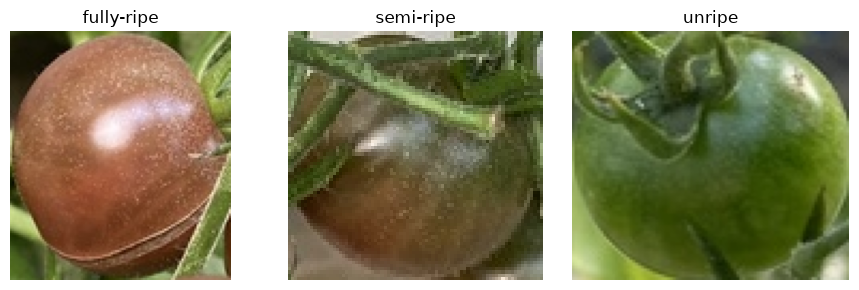

In [8]:
crops = som_common.pick_class_exemplar_crops(train_raw)
fig, axes = plt.subplots(1, len(crops), figsize=(3 * len(crops), 3))
if len(crops) == 1:
    axes = [axes]
for ax, (crop_img, label) in zip(axes, crops):
    ax.imshow(crop_img)
    ax.set_title(label)
    ax.axis("off")
plt.tight_layout()
plt.show()